
# ENSP355 – AI in Cyber Security Lab

## Lab 3: Classifying Cyber Activity Using a Simple Neural Network

**Objective:** Prepare a cyber activity dataset, build and train a simple neural network to classify **Normal/Attack** activity, evaluate the model using accuracy and loss graphs, test three new cyber activity records, and compare the neural network with a Decision Tree classifier.

> **Dataset required:** `simple_cyber_activity.csv`

This notebook follows the supplied Lab 3 manual for Q1–Q5. It uses the four specified input features:

- `failed_logins`
- `login_hour`
- `new_device`
- `data_transfer_mb`

Target label: `label` (`0 = Normal` / `1 = Attack`)



## Q1. CNN, RNN/LSTM and GAN Concept Matching

**Aim:** To understand different deep-learning models and identify their suitable applications in cyber security.

### Concept Matching Table

| Model | Suitable Data | Cyber-Security Example |
|---|---|---|
| CNN | Images / Grid-like Data | Malware image classification |
| RNN / LSTM | Sequences / Logs / Time Series | Sequential intrusion or authentication-log analysis |
| GAN | Synthetic Data Generation | Generate controlled synthetic attack samples |
| Dense Network | Small Numeric Feature Table | Normal/Attack classification |

### Why is a Dense Network Used in This Lab?

A dense neural network is used because the dataset contains four numeric input features. It can learn relationships between these features and classify cyber activity as Normal or Attack. It is simple to implement and suitable for this beginner-level classification task.

### Observation

CNNs are useful for image-based data, RNN/LSTM models are suitable for sequential data, and GANs can generate synthetic data. A dense neural network is appropriate for this lab because it works with a small table of numeric features.


## Q2: Dataset Preparation, Split and Normalization

**Objective:** Load the prepared cyber-activity dataset, separate the input features and target label, split the data into training and testing sets, and standardize the numeric features.

> **Dataset required:** `simple_cyber_activity.csv`

This section performs the following steps:

1. Load the cyber-activity dataset.
2. Select the four specified input features.
3. Separate input features (`X`) and target label (`y`).
4. Split the dataset into 75% training and 25% testing sets.
5. Apply StandardScaler to normalize the features.

**Input Features:**
- `failed_logins`
- `login_hour`
- `new_device`
- `data_transfer_mb`

**Target Label:** `label` (`0 = Normal` / `1 = Attack`)

**Normalization:** StandardScaler is used to bring numeric features onto a comparable scale. The scaler is fitted only on the training data and then applied to the testing data.

In [2]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load dataset
df = pd.read_csv('simple_cyber_activity.csv')

# Select input features
features = [
    'failed_logins',
    'login_hour',
    'new_device',
    'data_transfer_mb'
]

# Separate features and target
X = df[features]
y = df['label']

# Display class distribution
print("Class Distribution:")
print(y.value_counts().sort_index())

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Normalize features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Display shapes
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Class Distribution:
label
0    75
1    25
Name: count, dtype: int64
Training shape: (75, 4)
Testing shape: (25, 4)


## Q3: Build and Train the Neural Network

### AIM
To build a 4-8-4-1 dense neural network and train it for 20 epochs.

### Theory / Concept
- The input layer receives four feature values.
- Hidden layers learn combinations of the features.
- A sigmoid output produces a probability between 0 and 1.
- Binary cross-entropy is used for binary classification.
- One epoch is one complete pass through the training data.

### Algorithm / Guided Procedure
1. Create a Sequential model.
2. Add hidden layers with 8 and 4 ReLU neurons.
3. Add one sigmoid output neuron.
4. Compile with Adam, binary cross-entropy and accuracy.
5. Train for 20 epochs with validation_split=0.2.

In [3]:
import tensorflow as tf

np.random.seed(42)
tf.random.set_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(4, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=20,
    batch_size=8,
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81 (324.00 B)

 Trainable params: 81 (324.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.7500 - loss: 0.5869 - val_accuracy: 0.8000 - val_loss: 0.5127
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7500 - loss: 0.5789 - val_accuracy: 0.8000 - val_loss: 0.5053
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7500 - loss: 0.5722 - val_accuracy: 0.8000 - val_loss: 0.4963
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7500 - loss: 0.5659 - val_accuracy: 0.8000 - val_loss: 0.4871
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7500 - loss: 0.5594 - val_accuracy: 0.8000 - val_loss: 0.4782
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7500 - loss: 0.5529 - val_accuracy: 0.8000 - val_loss: 0.4696
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7500 - loss: 0.5464 - val_accuracy: 0.8000 - val_loss: 0.4615
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7500 - loss: 0.5402 - val_accuracy: 0.8000 - val_loss: 0.4531


## Q4: Accuracy/Loss Curves and Test Evaluation

### AIM
To plot learning curves, calculate test accuracy and interpret whether the model learned usefully.

### Theory / Concept
- Accuracy shows the proportion of correct classifications.
- Loss shows prediction error according to the selected loss function.
- Falling loss and stable validation accuracy suggest useful learning.
- A large gap between training and validation performance may indicate overfitting.

### Algorithm / Guided Procedure
1. Plot training and validation accuracy.
2. Plot training and validation loss.
3. Evaluate the model on the testing set.
4. Record test accuracy and test loss.
5. Write an interpretation of the curves.

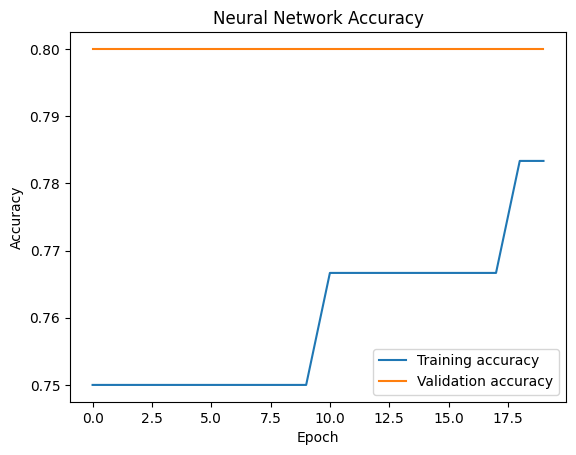

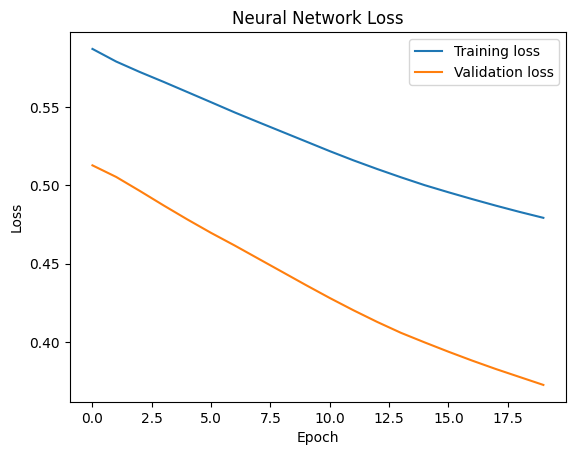

Test accuracy: 72.00%
Test loss: 0.5441


In [4]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(
    history.history['val_accuracy'],
    label='Validation accuracy'
)
plt.title('Neural Network Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Neural Network Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print(f'Test accuracy: {test_accuracy * 100:.2f}%')
print(f'Test loss: {test_loss:.4f}')

## Q5: New Predictions and Decision Tree Comparison

### AIM
To predict three new records and compare the neural network with a Decision Tree trained on the same split.

### Theory / Concept
- The neural network probability is converted to Attack when it is at least 0.50.
- Probabilities near 0.50 indicate uncertainty.
- A simpler model may be preferable when it performs similarly and is easier to explain.
- Agreement increases confidence; disagreement should trigger review.

### Algorithm / Guided Procedure
1. Create three new cyber-activity records.
2. Scale them using the fitted scaler.
3. Predict probabilities and labels.
4. Train a Decision Tree using the same training split.
5. Compare accuracy and new-record predictions.

In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

new_records = pd.DataFrame([
    {'failed_logins': 0, 'login_hour': 11,
     'new_device': 0, 'data_transfer_mb': 35},
    {'failed_logins': 7, 'login_hour': 1,
     'new_device': 1, 'data_transfer_mb': 250},
    {'failed_logins': 2, 'login_hour': 23,
     'new_device': 1, 'data_transfer_mb': 850}
])

new_scaled = scaler.transform(new_records)
probabilities = model.predict(new_scaled, verbose=0).flatten()

new_records['nn_probability'] = probabilities.round(3)
new_records['nn_prediction'] = np.where(
    probabilities >= 0.50,
    'Attack',
    'Normal'
)

tree = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

tree.fit(X_train, y_train)

tree_pred = tree.predict(X_test)
tree_accuracy = accuracy_score(y_test, tree_pred)

new_records['tree_prediction'] = np.where(
    tree.predict(new_records[features]) == 1,
    'Attack',
    'Normal'
)

print(f'Neural-network accuracy: {test_accuracy * 100:.2f}%')
print(f'Decision-tree accuracy: {tree_accuracy * 100:.2f}%')

display(new_records)

Neural-network accuracy: 72.00%
Decision-tree accuracy: 88.00%


,failed_logins,login_hour,new_device,data_transfer_mb,nn_probability,nn_prediction,tree_prediction
0,0,11,0,35,0.032,Normal,Normal
1,7,1,1,250,0.457,Normal,Attack
2,2,23,1,850,0.542,Attack,Attack


## Conclusion

In this lab, we classified cyber activities as Normal or Attack using a simple Artificial Neural Network. The dataset was prepared by selecting four numerical features and normalizing them using StandardScaler.

A neural network with the architecture 4-8-4-1 was created and trained for 20 epochs. Training and validation accuracy and loss graphs were plotted to understand the model's performance.

Three new cyber-activity records were tested, and their predictions were compared with a Decision Tree classifier. This comparison helped us understand how different machine learning models classify cyber activities.

Overall, this lab demonstrated how neural networks and machine learning techniques can be used for basic cyber-security activity classification.

## Lab 3: Final Submission Checklist

- [.] Q1: CNN, RNN/LSTM and GAN concept matching
- [.] Q2: Dataset preparation, splitting and normalization
- [.] Q3: Neural network model building and training
- [.] Q4: Accuracy and loss graphs with test evaluation
- [.] Q5: New predictions and Decision Tree comparison
- [.] Screenshots of code outputs and graphs
- [.] Final conclusion